In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

In [3]:
t = torch.linspace(0, 12 * torch.pi, steps=800)
wave = torch.sin(t)  # شکل: [800]

# ۳. ساخت پنجره لغزان با طول T = 20 برای پیش‌بینیِ نقطه بعدی (گام T+1)
seq_len = 20
X_list, y_list = [], []

for i in range(len(wave) - seq_len):
    window = wave[i : i + seq_len]        # ۲۰ نقطه متوالی
    target = wave[i + seq_len]            # نقطه بعد از پنجره
    X_list.append(window.unsqueeze(-1)) # شکل هر نمونه: [T=20, D=1]
    y_list.append(target.unsqueeze(-1)) # شکل هدف: [1]

X = torch.stack(X_list)  # شکل نهایی: [N, T=20, D=1]
y = torch.stack(y_list)  # شکل نهایی: [N, 1]

# ۴. تقسیم به Train و Test (۸۰٪ آموزش، ۲۰٪ تست)
split_idx = int(0.8 * len(X))
train_loader = DataLoader(
    TensorDataset(X[:split_idx], y[:split_idx]), batch_size=32, shuffle=True
)
test_loader = DataLoader(
    TensorDataset(X[split_idx:], y[split_idx:]), batch_size=32, shuffle=False
)

In [4]:
# ۵. تعریف مدل RNN ساده با کلاس nn.Module
class SimpleRNN(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x شکلش [N, T, D] است
        out, _ = self.rnn(x)      # out شکلش [N, T, hidden_size] است
        last_step = out[:, -1, :] # خروجیِ آخرین گام زمانیِ هر دنباله: [N, hidden_size]
        pred = self.fc(last_step) # پیش‌بینیِ مقدار بعدی: [N, 1]
        return pred

In [5]:
model = SimpleRNN(input_size=1, hidden_size=32, num_layers=1).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

In [7]:
epochs = 40
for epoch in range(1, epochs + 1):
    model.train()
    train_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        preds = model(batch_X)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(batch_X)

    train_loss /= len(train_loader.dataset)
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{epochs} | Train MSE Loss: {train_loss:.6f}")

# ۷. ارزیابی روی داده‌های تست و رسم نمودار
model.eval()
preds_list, actuals_list = [], []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        preds = model(batch_X).cpu()
        preds_list.append(preds)
        actuals_list.append(batch_y)

Epoch 01/40 | Train MSE Loss: 0.000015
Epoch 10/40 | Train MSE Loss: 0.000018
Epoch 20/40 | Train MSE Loss: 0.000004
Epoch 30/40 | Train MSE Loss: 0.000003
Epoch 40/40 | Train MSE Loss: 0.000019


In [8]:
test_preds = torch.cat(preds_list).squeeze(-1)
test_actuals = torch.cat(actuals_list).squeeze(-1)
test_mse = criterion(test_preds, test_actuals).item()
print(f"\nTest MSE Loss: {test_mse:.6f}")


Test MSE Loss: 0.000014


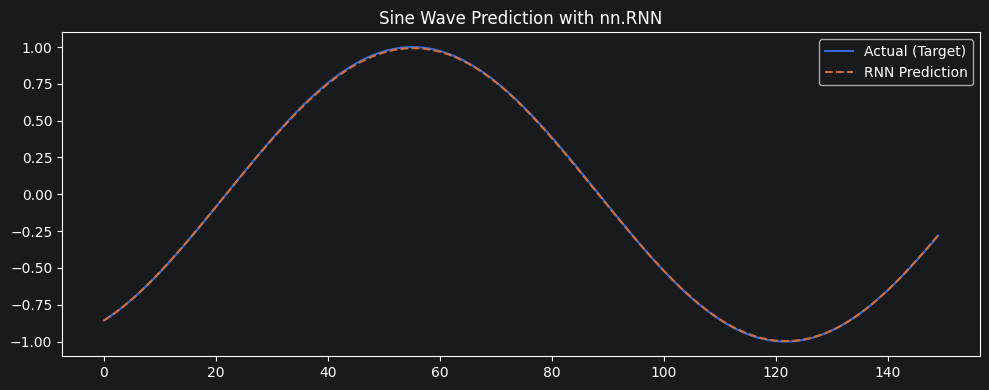

In [9]:
plt.figure(figsize=(10, 4))
plt.plot(test_actuals[:150].numpy(), label="Actual (Target)")
plt.plot(test_preds[:150].numpy(), label="RNN Prediction", linestyle="--")
plt.title("Sine Wave Prediction with nn.RNN")
plt.legend()
plt.tight_layout()
plt.show()